# Energy-Loss Analysis, Maintenance Priorities and CO₂ Impact

This notebook turns the regression output into the sustainability results of the project:

1. How much clean energy the turbine lost in 2018, and the equivalent CO₂.
2. Which suspected operating states the loss comes from.
3. When (month), at what wind speed, and from which wind direction the loss happens.
4. A ranked (Pareto) list of the conditions that cause most of the loss, to guide maintenance.
5. CO₂ scenarios for recovering part of the loss.

**Input:** `out/03_regression/model_results.csv` (every 10-minute record with the expected power from the XGBoost model).
**Outputs:** tables in `out/04_loss_analysis/` and figures `figures/05_*` to `figures/09_*`.

Loss is always reported against **two baselines**, giving a range:

- **Manufacturer baseline** – the theoretical power curve. Ideal test conditions, so it gives the *upper* estimate.
- **ML baseline** – the healthy power curve learned from this turbine's own normal-state data. It reflects real site behaviour, so it gives the *realistic recoverable* estimate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- CONFIG ----------------
INPUT_PATH = Path("../out/03_regression/model_results.csv")
OUT_DIR    = Path("../out/04_loss_analysis")
FIG_DIR    = Path("../figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

HOURS_PER_RECORD = 1 / 6      # each record is a 10-minute average
CO2_FACTOR       = 0.740      # tCO2 per MWh, Peninsular Malaysia grid (2024, provisional)

# Chart colours: one colour per baseline, used the same way in every figure
COLOR_ML    = "#2a78d6"   # ML baseline (blue)
COLOR_MANUF = "#eb6834"   # manufacturer baseline (orange)
COLOR_MUTED = "#8a8984"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
})
pd.options.display.float_format = "{:,.1f}".format

In [2]:
df = pd.read_csv(INPUT_PATH, parse_dates=["timestamp"])
print("Records:", f"{len(df):,}")
print("Columns used:", ["power_kw", "theo_power_kw", "predicted_power_kw",
                        "wind_speed", "ws_bin", "dir_sector", "month_name",
                        "rule_state", "cluster_state", "in_operating_region"])

Records: 50,530
Columns used: ['power_kw', 'theo_power_kw', 'predicted_power_kw', 'wind_speed', 'ws_bin', 'dir_sector', 'month_name', 'rule_state', 'cluster_state', 'in_operating_region']


## 1. Correcting the ML baseline below the operating range

The regression models were trained only on normal-state records with wind speed ≥ 3.5 m/s. Tree-based models cannot extrapolate: outside the training range they repeat the nearest value they learned. The check below shows that the model predicts roughly 43 kW even when there is **no wind at all**, which creates "loss" that cannot be real.

In [3]:
below = df[~df["in_operating_region"]]
check = (
    below.groupby(pd.cut(below["wind_speed"], [0, 1, 2, 3, 3.5], include_lowest=True), observed=True)
    .agg(records=("power_kw", "size"),
         mean_actual_kw=("power_kw", "mean"),
         mean_manufacturer_kw=("theo_power_kw", "mean"),
         mean_ml_predicted_kw=("predicted_power_kw", "mean"),
         ml_loss_mwh_as_given=("ml_shortfall_mwh", "sum"))
)
check

,records,mean_actual_kw,mean_manufacturer_kw,mean_ml_predicted_kw,ml_loss_mwh_as_given
wind_speed,,,,,
"(-0.001, 1.0]",824,0.0,0.0,42.6,5.9
"(1.0, 2.0]",2779,0.0,0.0,43.8,20.3
"(2.0, 3.0]",4146,0.9,0.0,43.4,29.4
"(3.0, 3.5]",2146,11.1,30.0,42.9,12.5


**Rule applied:** the ML baseline is used only inside the operating region (wind ≥ 3.5 m/s), where the model was trained. Below it, the manufacturer curve is used as the expected output (it is already near zero there). This removes about 68 MWh of artificial loss. All results below use this corrected ML baseline; the uncorrected total is printed for traceability with notebook 03.

In [4]:
# Expected power (kW) under each baseline
df["exp_manuf_kw"] = df["theo_power_kw"]
df["exp_ml_kw"] = np.where(df["in_operating_region"],
                           df["predicted_power_kw"],
                           df["theo_power_kw"])

# Energy (kWh) per 10-minute record
df["actual_kwh"]    = df["power_kw"].clip(lower=0) * HOURS_PER_RECORD
df["exp_manuf_kwh"] = df["exp_manuf_kw"] * HOURS_PER_RECORD
df["exp_ml_kwh"]    = df["exp_ml_kw"] * HOURS_PER_RECORD

# Loss = max(expected - actual, 0) x 1/6 h  (only shortfalls count)
df["loss_manuf_kwh"] = np.maximum(df["exp_manuf_kw"] - df["power_kw"], 0) * HOURS_PER_RECORD
df["loss_ml_kwh"]    = np.maximum(df["exp_ml_kw"]    - df["power_kw"], 0) * HOURS_PER_RECORD

print(f"ML loss as given in notebook 03 : {df['ml_shortfall_kwh'].sum()/1000:,.1f} MWh")
print(f"ML loss after correction       : {df['loss_ml_kwh'].sum()/1000:,.1f} MWh")
print(f"Manufacturer-baseline loss     : {df['loss_manuf_kwh'].sum()/1000:,.1f} MWh")

ML loss as given in notebook 03 : 677.9 MWh
ML loss after correction       : 617.5 MWh
Manufacturer-baseline loss     : 1,600.0 MWh


## 2. Headline: how much energy and CO₂ was lost in 2018

*Potential output* is what the turbine would have produced if every shortfall had been recovered: actual energy + loss. Loss share = loss ÷ potential output.

In [5]:
def loss_summary(loss_kwh, actual_kwh):
    loss_mwh = loss_kwh / 1000
    potential_mwh = (actual_kwh + loss_kwh) / 1000
    return loss_mwh, 100 * loss_mwh / potential_mwh, loss_mwh * CO2_FACTOR

actual_kwh = df["actual_kwh"].sum()
m_mwh, m_pct, m_co2 = loss_summary(df["loss_manuf_kwh"].sum(), actual_kwh)
l_mwh, l_pct, l_co2 = loss_summary(df["loss_ml_kwh"].sum(), actual_kwh)

zero = df["rule_state"] == "zero_output"

headline = pd.DataFrame({
    "measure": [
        "Actual energy generated (MWh)",
        "Energy lost (MWh)",
        "Loss as % of potential output",
        "Equivalent CO2 (tonnes)",
        "Zero-output intervals with wind >= 3.5 m/s",
        "Zero-output time (hours)",
    ],
    "manufacturer_baseline": [actual_kwh/1000, m_mwh, m_pct, m_co2, zero.sum(), zero.sum()*HOURS_PER_RECORD],
    "ml_baseline":           [actual_kwh/1000, l_mwh, l_pct, l_co2, zero.sum(), zero.sum()*HOURS_PER_RECORD],
})
headline

,measure,manufacturer_baseline,ml_baseline
0,Actual energy generated (MWh),"11,012.9","11,012.9"
1,Energy lost (MWh),"1,600.0",617.5
2,Loss as % of potential output,12.7,5.3
3,Equivalent CO2 (tonnes),"1,184.0",456.9
4,Zero-output intervals with wind >= 3.5 m/s,"2,220.0","2,220.0"
5,Zero-output time (hours),370.0,370.0


## 3. Loss by suspected operating state

The DBSCAN result in notebook 02 put 99.6 % of operating-region records into one cluster (cluster 0), so the clusters alone cannot split the loss into meaningful states. The table below shows this. For interpretation, the loss is therefore broken down by the **rule-based reference states** from notebook 01, which use simple physical checks (zero output in good wind, output well below the curve, etc.). These are suspected states, not confirmed faults.

In [6]:
def by_group(data, col, order=None):
    t = (data.groupby(col, observed=True)
         .agg(records=("power_kw", "size"),
              exp_ml_mwh=("exp_ml_kwh", "sum"),
              loss_ml_mwh=("loss_ml_kwh", "sum"),
              loss_manuf_mwh=("loss_manuf_kwh", "sum")))
    t[["exp_ml_mwh", "loss_ml_mwh", "loss_manuf_mwh"]] /= 1000
    t["hours"] = t["records"] * HOURS_PER_RECORD
    t["share_of_ml_loss_pct"] = 100 * t["loss_ml_mwh"] / t["loss_ml_mwh"].sum()
    t["share_of_manuf_loss_pct"] = 100 * t["loss_manuf_mwh"] / t["loss_manuf_mwh"].sum()
    # loss rate: how much of the expected (ML) energy in this group was lost
    t["ml_loss_rate_pct"] = 100 * t["loss_ml_mwh"] / t["exp_ml_mwh"].where(t["exp_ml_mwh"] > 0)
    t["co2_ml_t"] = t["loss_ml_mwh"] * CO2_FACTOR
    t["co2_manuf_t"] = t["loss_manuf_mwh"] * CO2_FACTOR
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    return t[["records", "hours", "loss_ml_mwh", "loss_manuf_mwh",
              "share_of_ml_loss_pct", "share_of_manuf_loss_pct",
              "ml_loss_rate_pct", "co2_ml_t", "co2_manuf_t"]]

print("Loss by DBSCAN cluster (for reference):")
display(by_group(df, "cluster_state")[["records", "loss_ml_mwh", "loss_manuf_mwh", "share_of_ml_loss_pct"]])

STATE_LABELS = {
    "zero_output": "Zero output (shutdown-like)",
    "underperforming": "Underperforming",
    "near_curve": "Near curve (normal)",
    "below_operating_range": "Below operating range",
}
state_table = by_group(df, "rule_state", order=list(STATE_LABELS))
state_table.index = state_table.index.map(STATE_LABELS)
state_table

Loss by DBSCAN cluster (for reference):


,records,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct
cluster_state,,,,
0,40476,556.2,"1,533.4",90.1
1,42,21.3,22.3,3.4
2,10,4.3,4.4,0.7
3,8,3.6,3.8,0.6
below_operating_range,9895,7.6,7.6,1.2
dbscan_noise,99,24.4,28.5,4.0


,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
rule_state,,,,,,,,,
Zero output (shutdown-like),2220,370.0,320.6,456.1,51.9,28.5,100.0,237.2,337.5
Underperforming,7218,"1,203.0",215.5,436.0,34.9,27.3,23.9,159.4,322.7
Near curve (normal),31197,"5,199.5",73.8,700.2,12.0,43.8,0.7,54.6,518.2
Below operating range,9895,"1,649.2",7.6,7.6,1.2,0.5,71.1,5.6,5.6


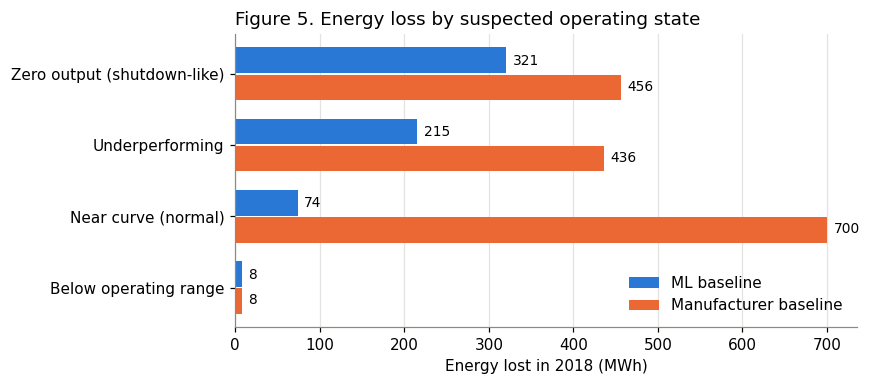

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(state_table))
h = 0.36
ax.barh(y - h/2 - 0.01, state_table["loss_ml_mwh"], height=h, color=COLOR_ML, label="ML baseline")
ax.barh(y + h/2 + 0.01, state_table["loss_manuf_mwh"], height=h, color=COLOR_MANUF, label="Manufacturer baseline")
for i, (ml, mf) in enumerate(zip(state_table["loss_ml_mwh"], state_table["loss_manuf_mwh"])):
    ax.text(ml + 8, i - h/2, f"{ml:,.0f}", va="center", fontsize=9)
    ax.text(mf + 8, i + h/2, f"{mf:,.0f}", va="center", fontsize=9)
ax.set_yticks(y, state_table.index)
ax.invert_yaxis()
ax.set_xlabel("Energy lost in 2018 (MWh)")
ax.set_title("Figure 5. Energy loss by suspected operating state", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_loss_by_state.png", bbox_inches="tight")
plt.show()

**How to read this.** Under the manufacturer curve, a large part of the loss sits in the "near curve" state – the turbine is running normally but slightly below the ideal curve, which is mostly site conditions rather than a fault. Under the ML baseline, which already reflects this site's normal behaviour, that part shrinks sharply. What remains is concentrated in the **zero-output (shutdown-like)** and **underperforming** states, which are the losses maintenance can realistically act on.

## 4. When the loss happens: by month

Two views are shown: total loss (MWh) and the **loss rate** (loss ÷ expected ML energy that month). Total loss is partly driven by how windy a month is; the loss rate shows in which months the turbine performed worst relative to what it could have produced.

In [8]:
month_table = by_group(df, "month_name", order=MONTHS)
month_table

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
month_name,,,,,,,,,
Jan,3817,636.2,226.5,341.1,36.7,21.3,22.1,167.6,252.4
Feb,4032,672.0,84.8,148.8,13.7,9.3,8.2,62.7,110.1
Mar,4463,743.8,35.2,95.1,5.7,5.9,2.5,26.0,70.4
Apr,4305,717.5,31.1,96.9,5.0,6.1,5.2,23.0,71.7
May,4449,741.5,19.5,92.4,3.2,5.8,3.3,14.4,68.4
Jun,4245,707.5,18.9,102.7,3.1,6.4,2.7,14.0,76.0
Jul,4464,744.0,16.0,79.9,2.6,5.0,4.5,11.9,59.1
Aug,4425,737.5,36.7,179.7,5.9,11.2,2.5,27.1,133.0
Sep,4000,666.7,12.1,84.4,2.0,5.3,1.3,8.9,62.5


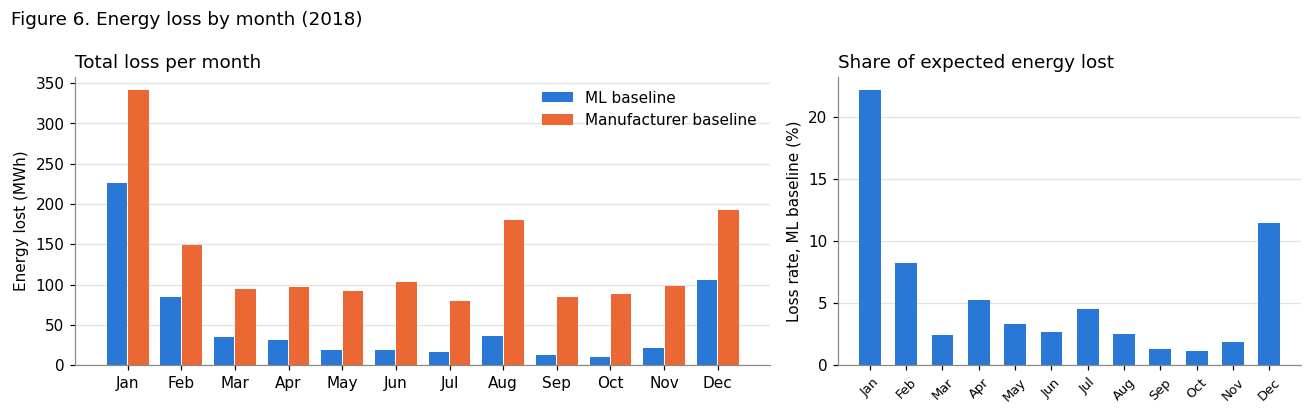

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(month_table))
w = 0.38
ax = axes[0]
ax.bar(x - w/2 - 0.01, month_table["loss_ml_mwh"], width=w, color=COLOR_ML, label="ML baseline")
ax.bar(x + w/2 + 0.01, month_table["loss_manuf_mwh"], width=w, color=COLOR_MANUF, label="Manufacturer baseline")
ax.set_xticks(x, month_table.index)
ax.set_ylabel("Energy lost (MWh)")
ax.set_title("Total loss per month", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)

ax = axes[1]
ax.bar(x, month_table["ml_loss_rate_pct"], width=0.6, color=COLOR_ML)
ax.set_xticks(x, month_table.index, fontsize=8.5, rotation=45)
ax.set_ylabel("Loss rate, ML baseline (%)")
ax.set_title("Share of expected energy lost", loc="left")
ax.grid(axis="x", visible=False)
fig.suptitle("Figure 6. Energy loss by month (2018)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_loss_by_month.png", bbox_inches="tight")
plt.show()

## 5. At what wind speed the loss happens

Loss per 0.5 m/s wind-speed bin (IEC power-curve practice). Losses in the middle of the curve point to underperformance; losses near and above rated wind speed point to power limitation or stops in strong wind, where every lost interval costs the most energy.

In [10]:
ws_table = by_group(df, "ws_bin").sort_index()
ws_table.loc[ws_table["loss_ml_mwh"] > 0.5]

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
ws_bin,,,,,,,,,
3.0,2146,357.7,7.6,7.6,1.2,0.5,71.1,5.6,5.6
3.5,1931,321.8,6.9,12.4,1.1,0.8,35.8,5.1,9.2
4.0,2030,338.3,7.9,18.3,1.3,1.1,18.9,5.8,13.6
4.5,1888,314.7,8.0,20.9,1.3,1.3,11.7,5.9,15.5
5.0,1927,321.2,10.0,27.9,1.6,1.7,9.6,7.4,20.6
5.5,2214,369.0,14.2,39.9,2.3,2.5,8.6,10.5,29.5
6.0,2429,404.8,21.0,55.8,3.4,3.5,8.9,15.5,41.3
6.5,2452,408.7,25.0,62.8,4.1,3.9,8.0,18.5,46.5
7.0,2411,401.8,29.4,72.8,4.8,4.6,7.6,21.8,53.9


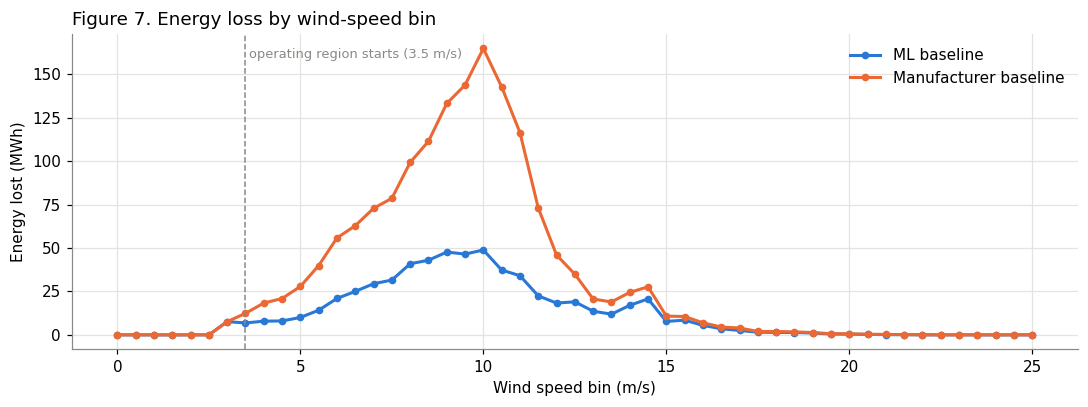

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ws_table.index, ws_table["loss_ml_mwh"], color=COLOR_ML, lw=2, marker="o", ms=4, label="ML baseline")
ax.plot(ws_table.index, ws_table["loss_manuf_mwh"], color=COLOR_MANUF, lw=2, marker="o", ms=4, label="Manufacturer baseline")
ax.axvline(3.5, color=COLOR_MUTED, lw=1, ls="--")
ax.text(3.6, ax.get_ylim()[1]*0.92, "operating region starts (3.5 m/s)", color=COLOR_MUTED, fontsize=8.5)
ax.set_xlabel("Wind speed bin (m/s)")
ax.set_ylabel("Energy lost (MWh)")
ax.set_title("Figure 7. Energy loss by wind-speed bin", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_loss_by_wind_speed.png", bbox_inches="tight")
plt.show()

## 6. Which wind direction the loss comes from

Loss per 30° sector (direction the wind blows **from**). As with months, the total depends on how often the wind blows from a sector, so the loss rate is also given. A sector with a high loss rate can point to yaw misalignment, wake from nearby turbines or terrain effects – things worth checking on site. Sectors with few hours of wind (for example 90–120°, about 250 hours) give less reliable rates, so check the `hours` column before drawing conclusions.

In [12]:
dir_order = (df[["dir_sector_start", "dir_sector"]].drop_duplicates()
             .sort_values("dir_sector_start")["dir_sector"].tolist())
dir_table = by_group(df, "dir_sector", order=dir_order)
dir_table

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
dir_sector,,,,,,,,,
0–30°,5216,869.3,113.8,245.6,18.4,15.3,13.9,84.2,181.7
30–60°,12569,"2,094.8",210.8,504.7,34.1,31.5,7.1,156.0,373.5
60–90°,10592,"1,765.3",97.6,388.5,15.8,24.3,3.8,72.2,287.5
90–120°,1497,249.5,7.0,9.3,1.1,0.6,15.8,5.2,6.9
120–150°,995,165.8,3.3,12.4,0.5,0.8,5.4,2.4,9.2
150–180°,1626,271.0,8.6,23.6,1.4,1.5,2.6,6.4,17.4
180–210°,7686,"1,281.0",88.5,202.5,14.3,12.7,3.1,65.5,149.8
210–240°,3902,650.3,43.5,106.1,7.1,6.6,4.5,32.2,78.5
240–270°,2305,384.2,21.3,53.9,3.5,3.4,10.0,15.8,39.9


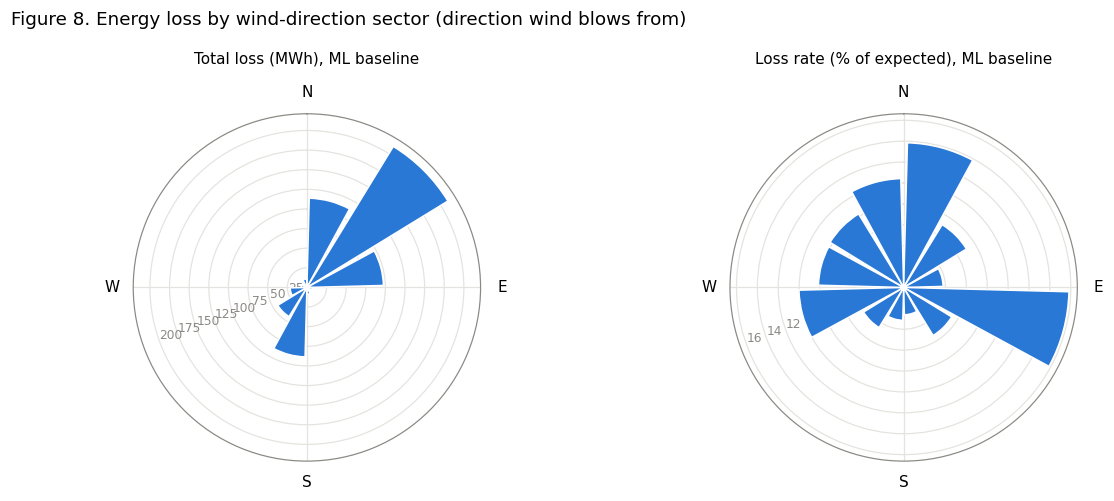

In [13]:
fig = plt.figure(figsize=(11, 4.6))
theta = np.deg2rad(np.arange(0, 360, 30) + 15)       # centre of each 30-degree sector
width = np.deg2rad(30) * 0.9
ml = dir_table["loss_ml_mwh"].reindex(dir_order).fillna(0).to_numpy()
rate = dir_table["ml_loss_rate_pct"].reindex(dir_order).fillna(0).to_numpy()

for k, (vals, title, unit) in enumerate([(ml, "Total loss (MWh)", "MWh"),
                                          (rate, "Loss rate (% of expected)", "%")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.bar(theta, vals, width=width, color=COLOR_ML, edgecolor="white", linewidth=1)
    ax.set_title(title + ", ML baseline", fontsize=10, pad=14)
    ax.set_xticks(np.deg2rad([0, 90, 180, 270]), ["N", "E", "S", "W"])
    ax.set_rlabel_position(250)
    ax.tick_params(axis="y", labelsize=8, colors=COLOR_MUTED)
    ax.grid(color="#e4e3df")
fig.suptitle("Figure 8. Energy loss by wind-direction sector (direction wind blows from)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_loss_by_direction.png", bbox_inches="tight")
plt.show()

## 7. Pareto ranking: where to look first

Each month × direction-sector combination is treated as one "condition". Conditions are ranked by ML-baseline loss, and the cumulative share shows how few of them account for most of the loss. The chart is split into two panels instead of using two y-axes, so each scale is read on its own.

In [14]:
cond = (df.groupby(["month", "month_name", "dir_sector"], observed=True)
        .agg(records=("power_kw", "size"),
             mean_wind_ms=("wind_speed", "mean"),
             loss_ml_mwh=("loss_ml_kwh", "sum"),
             loss_manuf_mwh=("loss_manuf_kwh", "sum"))
        .reset_index())
cond[["loss_ml_mwh", "loss_manuf_mwh"]] /= 1000
cond = cond[cond["loss_ml_mwh"] > 0].sort_values("loss_ml_mwh", ascending=False).reset_index(drop=True)
cond["rank"] = cond.index + 1
cond["share_pct"] = 100 * cond["loss_ml_mwh"] / cond["loss_ml_mwh"].sum()
cond["cumulative_pct"] = cond["share_pct"].cumsum()
cond["condition"] = cond["month_name"] + " · " + cond["dir_sector"]

n50 = int((cond["cumulative_pct"] < 50).sum() + 1)
n80 = int((cond["cumulative_pct"] < 80).sum() + 1)
print(f"Conditions with any loss: {len(cond)}")
print(f"{n50} conditions ({100*n50/len(cond):.0f}%) cause 50% of the ML-baseline loss")
print(f"{n80} conditions ({100*n80/len(cond):.0f}%) cause 80% of the ML-baseline loss")

Conditions with any loss: 134
6 conditions (4%) cause 50% of the ML-baseline loss
25 conditions (19%) cause 80% of the ML-baseline loss


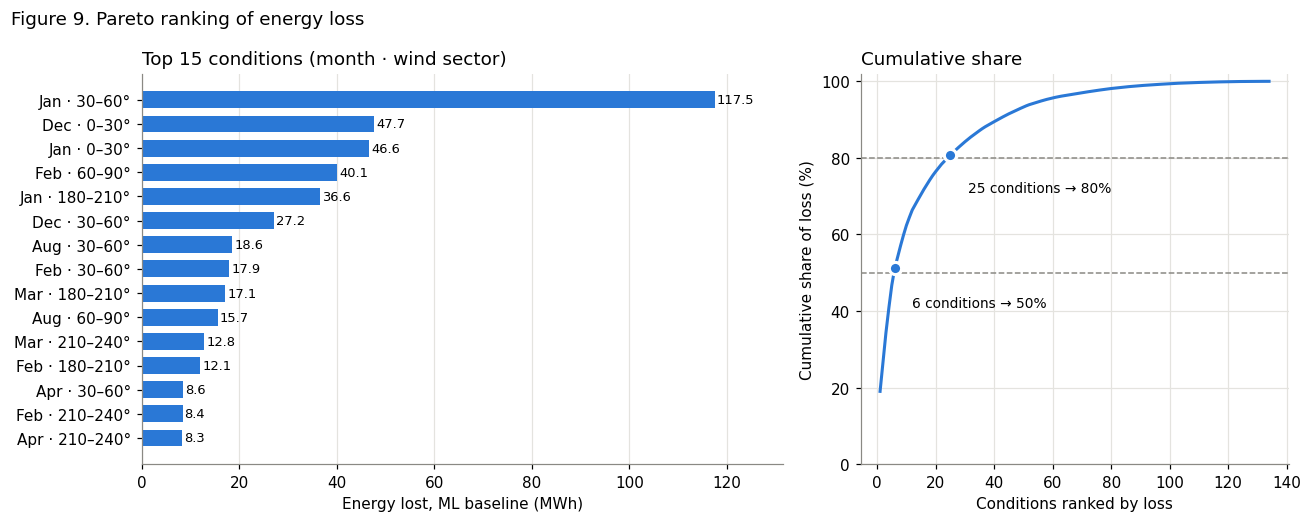

In [15]:
TOP_N = 15
top = cond.head(TOP_N)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [3, 2]})

ax = axes[0]
ax.barh(top["condition"], top["loss_ml_mwh"], color=COLOR_ML, height=0.7)
for i, v in enumerate(top["loss_ml_mwh"]):
    ax.text(v + 0.4, i, f"{v:,.1f}", va="center", fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, top["loss_ml_mwh"].max() * 1.12)
ax.set_xlabel("Energy lost, ML baseline (MWh)")
ax.set_title(f"Top {TOP_N} conditions (month · wind sector)", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.plot(cond["rank"], cond["cumulative_pct"], color=COLOR_ML, lw=2)
for n, p in [(n50, 50), (n80, 80)]:
    ax.axhline(p, color=COLOR_MUTED, lw=1, ls="--")
    ax.plot([n], [cond.loc[n-1, "cumulative_pct"]], "o", color=COLOR_ML, ms=8,
            markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"{n} conditions → {p}%", (n, p), xytext=(n + 6, p - 9), fontsize=9)
ax.set_xlabel("Conditions ranked by loss")
ax.set_ylabel("Cumulative share of loss (%)")
ax.set_ylim(0, 102)
ax.set_title("Cumulative share", loc="left")
fig.suptitle("Figure 9. Pareto ranking of energy loss", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_pareto_loss.png", bbox_inches="tight")
plt.show()

### Maintenance priority list

For each of the top conditions, the dominant suspected state (the state contributing most of that condition's loss) suggests what to check first. This is an **inspection focus, not a diagnosis** – it must be confirmed against maintenance logs or on-site inspection.

| Dominant state | Suggested inspection focus |
|---|---|
| Zero output | Review stop/fault logs for that period; check for unplanned shutdowns in good wind |
| Underperforming | Check yaw alignment, blade condition (soiling, damage, pitch) and anemometer calibration |
| Near curve | Check for power limitation or curtailment instructions near rated wind |

In [16]:
FOCUS = {
    "zero_output": "Review stop/fault logs; unplanned shutdowns in good wind",
    "underperforming": "Check yaw alignment, blades, pitch and anemometer",
    "near_curve": "Check power limitation / curtailment near rated wind",
    "below_operating_range": "Low wind; no action",
}

state_loss = (df.groupby(["month_name", "dir_sector", "rule_state"], observed=True)["loss_ml_kwh"]
              .sum().unstack(fill_value=0))
state_share = state_loss.div(state_loss.sum(axis=1), axis=0)

TOP_PRIORITY = 10
priority = cond.head(TOP_PRIORITY).copy()
idx = list(zip(priority["month_name"], priority["dir_sector"]))
priority["dominant_state"] = [state_share.loc[i].idxmax() for i in idx]
priority["dominant_state_share_pct"] = [100 * state_share.loc[i].max() for i in idx]
priority["co2_ml_t"] = priority["loss_ml_mwh"] * CO2_FACTOR
priority["hours"] = priority["records"] * HOURS_PER_RECORD
priority["suggested_focus"] = priority["dominant_state"].map(FOCUS)
priority = priority[["rank", "month_name", "dir_sector", "hours", "mean_wind_ms",
                     "loss_ml_mwh", "loss_manuf_mwh", "share_pct", "cumulative_pct",
                     "co2_ml_t", "dominant_state", "dominant_state_share_pct", "suggested_focus"]]
priority

,rank,month_name,dir_sector,hours,mean_wind_ms,loss_ml_mwh,loss_manuf_mwh,share_pct,cumulative_pct,co2_ml_t,dominant_state,dominant_state_share_pct,suggested_focus
0,1,Jan,30–60°,99.0,9.2,117.5,153.4,19.0,19.0,86.9,zero_output,69.7,Review stop/fault logs; unplanned shutdowns in...
1,2,Dec,0–30°,124.3,9.5,47.7,87.5,7.7,26.8,35.3,underperforming,52.0,"Check yaw alignment, blades, pitch and anemometer"
2,3,Jan,0–30°,62.7,8.3,46.6,77.8,7.5,34.3,34.5,underperforming,51.5,"Check yaw alignment, blades, pitch and anemometer"
3,4,Feb,60–90°,151.0,7.7,40.1,70.0,6.5,40.8,29.7,zero_output,82.6,Review stop/fault logs; unplanned shutdowns in...
4,5,Jan,180–210°,196.3,11.3,36.6,56.4,5.9,46.7,27.1,zero_output,78.5,Review stop/fault logs; unplanned shutdowns in...
5,6,Dec,30–60°,79.5,6.2,27.2,37.9,4.4,51.1,20.1,underperforming,54.9,"Check yaw alignment, blades, pitch and anemometer"
6,7,Aug,30–60°,372.2,9.5,18.6,90.6,3.0,54.1,13.8,near_curve,38.7,Check power limitation / curtailment near rate...
7,8,Feb,30–60°,93.0,7.5,17.9,27.5,2.9,57.1,13.3,underperforming,75.4,"Check yaw alignment, blades, pitch and anemometer"
8,9,Mar,180–210°,330.2,11.8,17.1,46.4,2.8,59.8,12.7,near_curve,37.1,Check power limitation / curtailment near rate...
9,10,Aug,60–90°,263.0,10.1,15.7,73.3,2.5,62.4,11.6,near_curve,35.8,Check power limitation / curtailment near rate...


## 8. CO₂ scenarios

These are **estimates**, not measured savings. They assume each recovered MWh of wind generation would displace grid electricity at Peninsular Malaysia's grid emission factor of 0.740 tCO₂/MWh (2024, provisional). The turbine itself is in Turkey; the Malaysian factor is used to express the impact in a Malaysian context.

In [17]:
zero_ml = df.loc[zero, "loss_ml_kwh"].sum() / 1000
under_ml = df.loc[df["rule_state"] == "underperforming", "loss_ml_kwh"].sum() / 1000

scenarios = pd.DataFrame({
    "scenario": [
        "Recover all zero-output (shutdown-like) loss",
        "Recover zero-output + underperforming loss",
        "Recover 50% of ML-baseline loss",
        "Recover all ML-baseline loss (realistic ceiling)",
        "Recover 50% of manufacturer-baseline loss (proposal scenario)",
        "Recover all manufacturer-baseline loss (theoretical ceiling)",
    ],
    "energy_mwh": [zero_ml, zero_ml + under_ml, 0.5 * l_mwh, l_mwh, 0.5 * m_mwh, m_mwh],
})
scenarios["co2_avoided_t"] = scenarios["energy_mwh"] * CO2_FACTOR
scenarios["pct_of_actual_generation"] = 100 * scenarios["energy_mwh"] / (actual_kwh / 1000)
scenarios

,scenario,energy_mwh,co2_avoided_t,pct_of_actual_generation
0,Recover all zero-output (shutdown-like) loss,320.6,237.2,2.9
1,Recover zero-output + underperforming loss,536.1,396.7,4.9
2,Recover 50% of ML-baseline loss,308.7,228.5,2.8
3,Recover all ML-baseline loss (realistic ceiling),617.5,456.9,5.6
4,Recover 50% of manufacturer-baseline loss (pro...,800.0,592.0,7.3
5,Recover all manufacturer-baseline loss (theore...,"1,600.0","1,184.0",14.5


## 9. Save outputs

In [18]:
headline.to_csv(OUT_DIR / "headline_loss.csv", index=False)
state_table.to_csv(OUT_DIR / "loss_by_state.csv")
month_table.to_csv(OUT_DIR / "loss_by_month.csv")
ws_table.to_csv(OUT_DIR / "loss_by_wind_speed.csv")
dir_table.to_csv(OUT_DIR / "loss_by_direction.csv")
cond.to_csv(OUT_DIR / "pareto_conditions.csv", index=False)
priority.to_csv(OUT_DIR / "maintenance_priority.csv", index=False)
scenarios.to_csv(OUT_DIR / "co2_scenarios.csv", index=False)
print("Saved:", sorted(p.name for p in OUT_DIR.glob("*.csv")))

Saved: ['co2_scenarios.csv', 'headline_loss.csv', 'loss_by_direction.csv', 'loss_by_month.csv', 'loss_by_state.csv', 'loss_by_wind_speed.csv', 'maintenance_priority.csv', 'pareto_conditions.csv']


## 10. Key findings (generated from the results above)

In [19]:
top1 = cond.iloc[0]
jan_dec = month_table.loc[["Jan", "Dec"], "share_of_ml_loss_pct"].sum()
print(f"1. In 2018 the turbine lost {l_mwh:,.0f} MWh against its own healthy curve "
      f"({l_pct:.1f}% of potential output, ~{l_co2:,.0f} t CO2) and {m_mwh:,.0f} MWh against "
      f"the manufacturer curve ({m_pct:.1f}%, ~{m_co2:,.0f} t CO2).")
print(f"2. Zero-output (shutdown-like) periods in good wind cause {state_table.iloc[0]['share_of_ml_loss_pct']:.0f}% "
      f"of the realistic loss in only {state_table.iloc[0]['hours']:,.0f} hours; underperformance adds "
      f"{state_table.iloc[1]['share_of_ml_loss_pct']:.0f}%.")
print(f"3. January and December together account for {jan_dec:.0f}% of the realistic loss.")
print(f"4. {n50} of {len(cond)} month-sector conditions cause half of the loss; the single largest is "
      f"{top1['condition']} ({top1['loss_ml_mwh']:,.0f} MWh, {top1['share_pct']:.0f}%).")
print(f"5. Recovering only the shutdown-like loss would avoid ~{scenarios.loc[0, 'co2_avoided_t']:,.0f} t CO2 per year "
      f"for this one turbine (estimate).")

1. In 2018 the turbine lost 617 MWh against its own healthy curve (5.3% of potential output, ~457 t CO2) and 1,600 MWh against the manufacturer curve (12.7%, ~1,184 t CO2).
2. Zero-output (shutdown-like) periods in good wind cause 52% of the realistic loss in only 370 hours; underperformance adds 35%.
3. January and December together account for 54% of the realistic loss.
4. 6 of 134 month-sector conditions cause half of the loss; the single largest is Jan · 30–60° (117 MWh, 19%).
5. Recovering only the shutdown-like loss would avoid ~237 t CO2 per year for this one turbine (estimate).


### Note for the regression notebook (03)

Notebook 03 reports a total ML loss of about 678 MWh. Around 68 MWh of that comes from records below 3.5 m/s, where the XGBoost model predicts ~43 kW even at zero wind because it was never trained there. This notebook corrects for it (Section 1), giving about 617 MWh. Notebook 03 could apply the same rule so both notebooks report the same figure.